<a href="https://colab.research.google.com/github/nkhanhhh/CausalForest_Uplift_Criteo/blob/main/Uplift_Benchmark_Criteo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Benchmark và cải tiến các giải thuật uplift trên dữ liệu Criteo

Giai đoạn 1 của dự án: **dùng mã nguồn có sẵn của các paper → so sánh công bằng trên cùng một quy trình → cải tiến để có kết quả cao hơn bài báo gốc**. Phần hệ thống BI (GA4 → BigQuery → Power BI) để giai đoạn sau.

| | |
|---|---|
| **Dữ liệu** | Criteo Uplift v2.1: 13.979.592 dòng, 12 đặc trưng ẩn danh `f0`–`f11`, treatment 85%, visit 4,70%, conversion 0,29%. Không có conversion nếu không có visit. |
| **Giải thuật gốc (tuần 4)** | 8 giải thuật, mã nguồn lấy từ thư viện: S-, T-, X-, R-, DR-learner và uplift random forest (CausalML), Causal Forest (EconML), class transformation (scikit-uplift) |
| **Cải tiến trong notebook này (tuần 6, 8)** | A1 (proxy) và A2 (phân rã theo phễu) trên S-, T-, X-learner: dùng visit để dự đoán uplift conversion tốt hơn |
| **Notebook đi kèm** | `DESCN_Criteo.ipynb`: TARNet, CFR, DESCN từ repo chính thức của paper DESCN và hai cải tiến A3 (TARNet + phễu), P (DESCN cân bằng propensity) |
| **Phần tự viết** | Hàm đánh giá (đối chiếu với scikit-uplift), lớp bọc các thư viện, quy trình chia dữ liệu và kiểm định, cải tiến A1, A2 |
| **Tiêu chí cải tiến** | Qini AUC cao hơn bản gốc ở ít nhất 4/5 seed và khoảng tin cậy bootstrap 95% của chênh lệch nằm hẳn trên 0 (mục 10) |

**Cách chạy:** mở bằng Google Colab → *Runtime → Run all*. Ô ở mục 2 hỏi quyền truy cập Google Drive: kết quả được lưu vào `MyDrive/uplift_project` ngay sau mỗi giải thuật, nên nếu Colab ngắt kết nối thì chạy lại, notebook tự bỏ qua phần đã xong.
- Đặt `TUAN` ở mục 2 theo tuần đang làm: `4` = 8 giải thuật gốc; `6` = thêm A1, A2; `8` = thêm phân tích theo cỡ mẫu.
- Lần đầu đặt `QUICK_RUN = True` để thử toàn bộ code trên mẫu nhỏ (khoảng 15–20 phút). Kết quả chạy thử lưu riêng vào `results_quick/`.
- Cấu hình đầy đủ của tuần 4 (visit 1 triệu dòng, conversion 4 triệu dòng, 5 seed) mất khoảng 2–2,5 giờ trên Colab miễn phí; tuần 6 thêm khoảng 40 phút; tuần 8 thêm khoảng 30 phút. Có thể chạy làm nhiều lần, ví dụ `OUTCOMES = ["visit"]` trước rồi `["conversion"]` sau.

| Mục | Nội dung | Tuần |
|---|---|---|
| 1–3 | Cài thư viện, cấu hình, hàm đánh giá | 3 |
| 4 | Các giải thuật gốc từ mã nguồn có sẵn và cải tiến A1, A2 | 3, 6 |
| 5 | Kiểm tra trên dữ liệu mô phỏng có uplift thật | 3, 6 |
| 6 | Tải và kiểm tra dữ liệu Criteo | 3 |
| 7–9 | Chạy benchmark, tổng hợp, vẽ hình | 4, 6 |
| 10 | Đối chiếu tiêu chí: cải tiến so với bản gốc | 6, 8 |
| 11 | Phân tích theo cỡ mẫu | 8 |

## 1. Cài thư viện
Cài đúng phiên bản đã thử để kết quả chạy lại được. Nếu Colab báo cần khởi động lại phiên (*Restart session*), bấm khởi động lại rồi chạy lại từ đầu. Ô này in phiên bản thư viện (minh chứng Hình 3.1).

In [ ]:
%pip install -q kagglehub causalml==0.17.0 econml==0.17.0 scikit-uplift==0.5.1
import sys
from importlib.metadata import version
print("Python", sys.version.split()[0], "|", " | ".join(
    f"{p} {version(p)}" for p in ["numpy", "pandas", "scikit-learn", "lightgbm", "causalml", "econml", "scikit-uplift"]))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 33.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 90.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 75.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.3/155.3 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.4/268.4 kB 18.9 MB/s eta 0:00:0

## 2. Cấu hình
- `TUAN`: tuần đang làm, quyết định chạy những gì (xem đầu notebook).
- `N_SAMPLE`: số dòng lấy mẫu cho từng outcome. Conversion rất hiếm nên cần nhiều dòng hơn visit.
- `SEEDS`: mỗi seed là một lần chia train/validation/test khác nhau; kết quả báo cáo là trung bình ± độ lệch chuẩn qua các seed.
- `MAX_TRAIN`: uplift random forest và Causal Forest chạy chậm nên chỉ học trên một mẫu con của tập train; ghi rõ cỡ mẫu này trong báo cáo.
- `SIZE_PAIR`, `SIZE_FRACTIONS` (tuần 8): cặp bản gốc – cải tiến dùng để phân tích theo cỡ mẫu; chọn cặp có kết quả tốt nhất ở tuần 6.
- Mô hình nền LightGBM có tham số cố định. Nếu chọn tham số, chỉ chọn trên **tập validation**, không bao giờ dùng tập test.
- Notebook `DESCN_Criteo.ipynb` phải dùng cùng `N_SAMPLE`, `SEEDS`, `VAL_SIZE`, `TEST_SIZE`, `DATA_PATH` để có cùng tập test.
- `RESUME = True` bỏ qua các lần chạy đã có trong `benchmark_metrics.csv`. Nếu đổi cấu hình (cỡ mẫu, `MAX_TRAIN`, tham số mô hình), đổi tên thư mục `results` cũ trước khi chạy lại.

In [ ]:
import os, time, glob, gzip, hashlib, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier, LGBMRegressor

warnings.filterwarnings("ignore")
logging.getLogger("causalml").setLevel(logging.WARNING)

TUAN      = 4      # 4: 8 giải thuật gốc | 6: thêm cải tiến A1, A2 | 8: thêm phân tích theo cỡ mẫu
QUICK_RUN = False  # True = chạy thử toàn bộ code trên mẫu nhỏ, 1 seed; KHÔNG dùng số liệu này cho báo cáo
OUTCOMES  = ["visit", "conversion"]
N_SAMPLE  = {"visit": 1_000_000, "conversion": 4_000_000}
SEEDS     = [0, 1, 2, 3, 4]
VAL_SIZE, TEST_SIZE = 0.2, 0.3       # train/validation/test = 50/20/30
DATA_PATH = None                      # None = tự tải từ Kaggle; hoặc đường dẫn tới file criteo-uplift-v2.1.csv
USE_DRIVE = True                      # lưu kết quả vào Google Drive để không mất khi Colab ngắt kết nối
RESUME    = True                      # chạy lại thì bỏ qua các lần (outcome, seed, giải thuật) đã có kết quả
MAX_TRAIN = {"Uplift random forest": 200_000, "Causal Forest": 300_000}
N_BOOT    = 200                       # số lần bootstrap khi đối chiếu tiêu chí (mục 10)
SIZE_PAIR = ("T-learner", "A2 phễu (T-learner)")   # tuần 8: bản gốc, cải tiến
SIZE_FRACTIONS = [0.25, 0.5]                        # tuần 8: học trên 25%, 50% tập train

if QUICK_RUN:
    TUAN = 8
    N_SAMPLE = {"visit": 200_000, "conversion": 400_000}
    SEEDS = [0]
    MAX_TRAIN = {"Uplift random forest": 30_000, "Causal Forest": 60_000}
    N_BOOT = 20

LGBM_CLF = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=200,
                subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_jobs=-1, verbose=-1)
LGBM_REG = dict(LGBM_CLF)             # mô hình hồi quy (trong X-, R-, DR-learner) cùng tham số

FEATURES = [f"f{i}" for i in range(12)]
LABELS   = ["treatment", "conversion", "visit", "exposure"]

PROJECT_DIR = "."
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = "/content/drive/MyDrive/uplift_project"
    except ImportError:
        print("Không chạy trên Colab: lưu kết quả vào thư mục hiện tại")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results_quick" if QUICK_RUN else "results")
FIG_DIR     = os.path.join(PROJECT_DIR, "figures_quick" if QUICK_RUN else "figures")
PRED_DIR    = os.path.join(RESULTS_DIR, "preds")      # dự đoán trên tập test của seed đầu tiên (để vẽ hình)
for folder in (RESULTS_DIR, FIG_DIR, PRED_DIR):
    os.makedirs(folder, exist_ok=True)
print("Kết quả lưu tại:", os.path.abspath(RESULTS_DIR))

print("Cấu hình:", {"TUAN": TUAN, "QUICK_RUN": QUICK_RUN, "N_SAMPLE": N_SAMPLE, "SEEDS": SEEDS, "MAX_TRAIN": MAX_TRAIN})

Mounted at /content/drive
Kết quả lưu tại: /content/drive/MyDrive/uplift_project/results
Cấu hình: {'TUAN': 4, 'QUICK_RUN': False, 'N_SAMPLE': {'visit': 1000000, 'conversion': 4000000}, 'SEEDS': [0, 1, 2, 3, 4], 'MAX_TRAIN': {'Uplift random forest': 200000, 'Causal Forest': 300000}}


## 3. Hàm đánh giá (tự viết)
Không quan sát được uplift của từng người (mỗi người chỉ thuộc treatment **hoặc** control), nên đánh giá theo nhóm: xếp khách theo uplift dự đoán giảm dần rồi xem nhóm đứng đầu có chênh lệch treatment − control thực tế lớn hơn không.
- **Qini AUC, AUUC (chuẩn hoá):** phần diện tích giữa đường của mô hình và đường chọn ngẫu nhiên, chia cho phần diện tích của mô hình lý tưởng. 0 = như ngẫu nhiên, 1 = hoàn hảo. Mục 5a đối chiếu với thư viện scikit-uplift.
- **Uplift@k:** chênh lệch tỷ lệ outcome treatment − control thực tế trong top k% khách.
- **So sánh hai mô hình:** chênh lệch theo từng seed, số seed thắng, p-value kiểm định t ghép cặp; `bootstrap_diff` cho khoảng tin cậy 95% trên tập test.

Mọi giải thuật dùng chung một hàm đánh giá này, nên chênh lệch giữa các giải thuật không đến từ cách tính chỉ số khác nhau.

In [ ]:
from sklearn.metrics import auc

def _cumulative(y, t, score):
    # Cộng dồn theo uplift dự đoán giảm dần; các điểm có cùng score được gộp lại
    order = np.argsort(-score, kind="mergesort")
    y, t, score = y[order].astype(float), t[order].astype(float), score[order]
    ends = np.r_[np.flatnonzero(np.diff(score)), len(score) - 1]
    n = ends + 1.0
    n_t = np.cumsum(t)[ends]
    y_t = np.cumsum(y * t)[ends]
    y_c = np.cumsum(y * (1 - t))[ends]
    return n, n_t, n - n_t, y_t, y_c

def _div(a, b):
    return np.divide(a, b, out=np.zeros_like(a), where=b != 0)

def qini_curve(y, t, score):
    n, n_t, n_c, y_t, y_c = _cumulative(y, t, score)
    return np.r_[0, n], np.r_[0, y_t - y_c * _div(n_t, n_c)]

def uplift_curve(y, t, score):
    n, n_t, n_c, y_t, y_c = _cumulative(y, t, score)
    return np.r_[0, n], np.r_[0, (_div(y_t, n_t) - _div(y_c, n_c)) * n]

def _normalized_area(curve, y, t, score, perfect_score):
    x, v = curve(y, t, score)
    xp, vp = curve(y, t, perfect_score)
    random_area = auc([0, xp[-1]], [0, vp[-1]])
    return (auc(x, v) - random_area) / (auc(xp, vp) - random_area)

def qini_auc_score(y, t, score):
    perfect = y * t - y * (1 - t)
    return _normalized_area(qini_curve, y, t, score, perfect.astype(float))

def uplift_auc_score(y, t, score):
    ctrl_resp = np.sum((y == 1) & (t == 0))
    treat_nonresp = np.sum((y == 0) & (t == 1))
    perfect = 2 * (y == t) + (y if ctrl_resp > treat_nonresp else t)
    return _normalized_area(uplift_curve, y, t, score, perfect.astype(float))

def uplift_at_k(y, t, score, k):
    # Thứ tự khi trùng điểm giống scikit-uplift để hai bên cho cùng kết quả
    top = np.argsort(score, kind="mergesort")[::-1][: int(len(score) * k)]
    return y[top][t[top] == 1].mean() - y[top][t[top] == 0].mean()

def uplift_by_decile(y, t, score, n_bins=10):
    # Uplift thực tế (treatment − control) và uplift dự đoán trong từng nhóm 10% khách
    d = pd.DataFrame({"y": y, "t": t, "score": score})
    d["decile"] = pd.qcut(d["score"].rank(method="first", ascending=False), n_bins, labels=False) + 1
    g1, g0 = d[d.t == 1].groupby("decile")["y"], d[d.t == 0].groupby("decile")["y"]
    out = pd.DataFrame({"n_treatment": g1.size(), "n_control": g0.size(),
                        "rate_treatment": g1.mean(), "rate_control": g0.mean()})
    out["actual_uplift"] = out.rate_treatment - out.rate_control
    out["actual_uplift_se"] = np.sqrt(out.rate_treatment * (1 - out.rate_treatment) / out.n_treatment
                                      + out.rate_control * (1 - out.rate_control) / out.n_control)
    out["predicted_uplift"] = d.groupby("decile")["score"].mean()
    return out.rename_axis("decile").reset_index()

def evaluate(y, t, score):
    # Các chỉ số trên một tập (thường là tập test); score phải là mảng 1 chiều
    score = np.asarray(score, dtype=float).ravel()
    assert score.shape[0] == len(y), "score phải là mảng 1 chiều, cùng số dòng với y"
    return {"qini_auc": qini_auc_score(y, t, score), "auuc": uplift_auc_score(y, t, score),
            "uplift_at_10": uplift_at_k(y, t, score, 0.1), "uplift_at_20": uplift_at_k(y, t, score, 0.2),
            "uplift_at_30": uplift_at_k(y, t, score, 0.3)}

def summarize(res, metrics=("qini_auc", "auuc", "uplift_at_10")):
    # Bảng trung bình ± độ lệch chuẩn qua các seed
    g = res.groupby(["outcome", "model"])[list(metrics)]
    mean, std = g.mean(), g.std(ddof=1)
    out = mean.copy().astype(object)
    for m in metrics:
        out[m] = [f"{a:.4f} ± {b:.4f}" if pd.notna(b) else f"{a:.4f}" for a, b in zip(mean[m], std[m])]
    out["n_seeds"] = g.size()
    return out

def compare(res, outcome, model_a, model_b, metric="qini_auc"):
    # So sánh cặp theo từng seed
    a = res[(res.outcome == outcome) & (res.model == model_a)].set_index("seed")[metric]
    b = res[(res.outcome == outcome) & (res.model == model_b)].set_index("seed")[metric]
    d = (a - b).dropna()
    p = stats.ttest_rel(a[d.index], b[d.index]).pvalue if len(d) > 1 else np.nan
    return {"outcome": outcome, "A": model_a, "B": model_b, "metric": metric, "mean_diff": d.mean(),
            "wins_A": int((d > 0).sum()), "n_seeds": len(d), "p_value": p}

def bootstrap_diff(y, t, score_a, score_b, metric=qini_auc_score, n_boot=200, seed=0):
    # Khoảng tin cậy 95% (bootstrap trên tập test) cho metric(A) − metric(B)
    rng = np.random.default_rng(seed)
    n = len(y)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        diffs.append(metric(y[i], t[i], score_a[i]) - metric(y[i], t[i], score_b[i]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return float(np.mean(diffs)), float(lo), float(hi)

import re, unicodedata

def slug(name):
    # Tên an toàn cho tên file và tham số dòng lệnh: bỏ dấu tiếng Việt, thay ký tự đặc biệt bằng "_"
    s = unicodedata.normalize("NFKD", name).replace("đ", "d").replace("Đ", "D")
    s = s.encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Za-z0-9]+", "_", s).strip("_")

def pred_path(outcome, name):
    # File dự đoán trên tập test (seed đầu tiên) của một giải thuật
    return os.path.join(PRED_DIR, f"{outcome}__{slug(name)}.npz")

## 4. Các giải thuật
### 4a. Giải thuật gốc từ mã nguồn có sẵn
Mỗi giải thuật dùng bản cài đặt có sẵn trong thư viện; phần tự viết chỉ là **lớp bọc** đưa về cùng giao diện `fit(X, t, y, visit=None)` và `predict_uplift(X)` (trả về mảng 1 chiều τ(x) = P(Y=1 | x, T=1) − P(Y=1 | x, T=0)). Tham số `visit` dùng cho các cải tiến ở mục 4b; các giải thuật gốc bỏ qua nó.

| Giải thuật | Paper | Mã nguồn sử dụng | Lưu ý khi dùng |
|---|---|---|---|
| S-learner | Künzel và cs. (2019) | CausalML `BaseSClassifier` | |
| T-learner | Künzel và cs. (2019) | CausalML `BaseTClassifier` | |
| X-learner | Künzel và cs. (2019) | CausalML `BaseXClassifier` | Truyền propensity = tỷ lệ treatment (dữ liệu A/B test) để thư viện không phải tự ước lượng |
| R-learner | Nie & Wager (2021) | CausalML `BaseRClassifier` | Thư viện tự làm cross-fitting 5 phần; truyền propensity như trên |
| DR-learner | Kennedy (2023) | CausalML `BaseDRRegressor` | Dùng bản Regressor (hồi quy trên nhãn 0/1): ở CausalML 0.17.0, `BaseDRClassifier` tạo pseudo-outcome bằng `predict()` của mô hình outcome, với bộ phân loại hàm này trả về nhãn 0/1 chứ không phải xác suất |
| Class transformation | Jaskowski & Jaroszewicz (2012) | scikit-uplift `ClassTransformation` | Phương pháp giả định hai nhóm cân bằng; Criteo lệch 85/15 nên truyền thêm trọng số 0,5/e cho treatment và 0,5/(1 − e) cho control |
| Uplift random forest | Rzepakowski & Jaroszewicz (2012) | CausalML `UpliftRandomForestClassifier` | Tiêu chí chia nhánh KL; nhãn treatment phải là chuỗi; huấn luyện và dự đoán đều chậm nên học trên mẫu con (`MAX_TRAIN`), dùng 20 cây sâu tối đa 6 |
| Causal Forest | Wager & Athey (2018); Athey và cs. (2019) | EconML `CausalForestDML` | Propensity là hằng số (`DummyClassifier`); `effect()` trả về mảng (n, 1) nên phải `.ravel()`; học trên mẫu con |

In [ ]:
from causalml.inference.meta import (BaseSClassifier, BaseTClassifier, BaseXClassifier,
                                     BaseRClassifier, BaseDRRegressor)
from causalml.inference.tree import UpliftRandomForestClassifier
from econml.dml import CausalForestDML
from sklift.models import ClassTransformation
from sklearn.dummy import DummyClassifier

def make_clf(seed):
    return LGBMClassifier(**LGBM_CLF, random_state=seed)

def make_reg(seed):
    return LGBMRegressor(**LGBM_REG, random_state=seed)

class UpliftModel:
    # Lớp cha: lưu seed; các lớp con gọi thư viện trong fit và predict_uplift
    def __init__(self, seed=0):
        self.seed = seed

class SLearner(UpliftModel):
    def fit(self, X, t, y, visit=None):
        self.m = BaseSClassifier(learner=make_clf(self.seed), control_name=0)
        self.m.fit(X, t, y)
        return self
    def predict_uplift(self, X):
        return np.ravel(self.m.predict(X))

class TLearner(UpliftModel):
    def fit(self, X, t, y, visit=None):
        self.m = BaseTClassifier(learner=make_clf(self.seed), control_name=0)
        self.m.fit(X, t, y)
        return self
    def predict_uplift(self, X):
        return np.ravel(self.m.predict(X))

class XLearner(UpliftModel):
    def fit(self, X, t, y, visit=None):
        self.e = float(t.mean())                  # A/B test: propensity là hằng số
        self.m = BaseXClassifier(outcome_learner=make_clf(self.seed), effect_learner=make_reg(self.seed),
                                 control_name=0)
        self.m.fit(X, t, y, p=np.full(len(y), self.e))
        return self
    def predict_uplift(self, X):
        return np.ravel(self.m.predict(X, p=np.full(len(X), self.e)))

class RLearner(UpliftModel):
    def fit(self, X, t, y, visit=None):
        self.m = BaseRClassifier(outcome_learner=make_clf(self.seed), effect_learner=make_reg(self.seed),
                                 control_name=0, n_fold=5, random_state=self.seed)
        self.m.fit(X, t, y, p=np.full(len(y), float(t.mean())), verbose=False)
        return self
    def predict_uplift(self, X):
        return np.ravel(self.m.predict(X))

class DRLearner(UpliftModel):
    def fit(self, X, t, y, visit=None):
        self.m = BaseDRRegressor(learner=make_reg(self.seed), control_name=0)
        self.m.fit(X, t, y, p=np.full(len(y), float(t.mean())), seed=self.seed)
        return self
    def predict_uplift(self, X):
        return np.ravel(self.m.predict(X))

class ClassTransformationModel(UpliftModel):
    def fit(self, X, t, y, visit=None):
        e = float(t.mean())
        w = np.where(t == 1, 0.5 / e, 0.5 / (1 - e))   # đưa hai nhóm về cân bằng
        self.m = ClassTransformation(estimator=make_clf(self.seed))
        self.m.fit(X, y, t, estimator_fit_params={"sample_weight": w})
        return self
    def predict_uplift(self, X):
        return np.ravel(self.m.predict(X))

class UpliftRF(UpliftModel):
    def fit(self, X, t, y, visit=None):
        self.m = UpliftRandomForestClassifier(control_name="control", n_estimators=20, max_depth=6,
                                              min_samples_leaf=200, min_samples_treatment=50, n_reg=100,
                                              evaluationFunction="KL", random_state=self.seed, n_jobs=-1)
        self.m.fit(X, treatment=np.where(t == 1, "treatment", "control"), y=y)
        return self
    def predict_uplift(self, X):
        return np.ravel(self.m.predict(X))

class CausalForest(UpliftModel):
    def fit(self, X, t, y, visit=None):
        self.m = CausalForestDML(model_y=make_clf(self.seed), model_t=DummyClassifier(strategy="prior"),
                                 discrete_outcome=True, discrete_treatment=True, cv=3,
                                 n_estimators=200, min_samples_leaf=200, max_samples=0.25,
                                 random_state=self.seed, n_jobs=-1)
        self.m.fit(y, t, X=X)
        return self
    def predict_uplift(self, X):
        return np.ravel(self.m.effect(X, T0=0, T1=1))   # effect() trả về (n, 1) → làm phẳng

MODELS = {
    "S-learner": SLearner, "T-learner": TLearner, "X-learner": XLearner, "R-learner": RLearner,
    "DR-learner": DRLearner, "Class transformation": ClassTransformationModel,
    "Uplift random forest": UpliftRF, "Causal Forest": CausalForest,
}

def limit_train(idx, name, seed):
    # Lấy ngẫu nhiên một phần tập train: MAX_TRAIN[name] là số dòng tối đa, hoặc tỷ lệ nếu ≤ 1
    cap = MAX_TRAIN.get(name)
    if cap is None:
        return idx
    if cap <= 1:
        cap = int(len(idx) * cap)
    if len(idx) <= cap:
        return idx
    return np.random.default_rng(seed).choice(idx, size=cap, replace=False)

print("Giải thuật gốc:", list(MODELS))

ERROR:duecredit:Failed to import duecredit due to No module named 'duecredit'


Giải thuật gốc: ['S-learner', 'T-learner', 'X-learner', 'R-learner', 'DR-learner', 'Class transformation', 'Uplift random forest', 'Causal Forest']


### 4b. Cải tiến A1, A2: dùng visit để dự đoán uplift conversion (tuần 6, phần tự viết)
Conversion chỉ 0,29% nên mô hình học trực tiếp trên conversion có rất ít mẫu dương, nhất là ở nhóm đối chứng 15%. Visit phổ biến hơn khoảng 16 lần và conversion chỉ xảy ra sau visit.

| Cải tiến | Cách làm | So với bản gốc |
|---|---|---|
| **A1 proxy** | Học giải thuật nền trên visit, xếp hạng khách theo uplift visit dự đoán; vẫn đánh giá trên conversion | Cùng giải thuật học trên conversion |
| **A2 phân rã theo phễu** | P(C = 1 \| x, t) = P(V = 1 \| x, t) · P(C = 1 \| V = 1, x, t). Học P(V \| x, t) trên toàn bộ tập train và P(C \| V = 1, x, t) chỉ trên khách đã visit (conversion khoảng 6%), bằng meta-learner của CausalML. Uplift = p_V(x, 1)·p_C\|V(x, 1) − p_V(x, 0)·p_C\|V(x, 0) | Cùng meta-learner học trên conversion |

Các cải tiến chỉ chạy cho outcome conversion, khi `TUAN ≥ 6`. Mỗi cải tiến ghi kèm bản gốc để mục 10 so sánh.

In [ ]:
def components(m, X):
    # Xác suất dự đoán của từng nhóm từ meta-learner của CausalML: (nhóm đối chứng, nhóm treatment)
    _, yc, yt = m.predict(X, return_components=True)
    k = list(yt)[0]
    return np.ravel(yc[k]), np.ravel(yt[k])

class Proxy(UpliftModel):
    # A1: học giải thuật nền trên visit thay cho conversion
    base = TLearner
    def fit(self, X, t, y, visit=None):
        self.m = self.base(seed=self.seed).fit(X, t, visit)
        return self
    def predict_uplift(self, X):
        return self.m.predict_uplift(X)

class Funnel(UpliftModel):
    # A2: P(C | x, t) = P(V | x, t) · P(C | V = 1, x, t), mỗi phần học bằng một meta-learner của CausalML
    learner = BaseTClassifier
    def fit(self, X, t, y, visit=None):
        self.mv = self.learner(learner=make_clf(self.seed), control_name=0)
        self.mv.fit(X, t, visit)                              # P(visit | x, t): toàn bộ tập train
        v1 = visit == 1
        self.mc = self.learner(learner=make_clf(self.seed), control_name=0)
        self.mc.fit(X[v1], t[v1], y[v1])                      # P(conversion | visit = 1, x, t): chỉ khách đã visit
        return self
    def predict_uplift(self, X):
        pv0, pv1 = components(self.mv, X)
        pc0, pc1 = components(self.mc, X)
        return pv1 * pc1 - pv0 * pc0

class ProxyS(Proxy): base = SLearner
class ProxyT(Proxy): base = TLearner
class ProxyX(Proxy): base = XLearner
class FunnelS(Funnel): learner = BaseSClassifier
class FunnelT(Funnel): learner = BaseTClassifier

IMPROVEMENTS = {   # tên: (lớp, bản gốc để so sánh)
    "A1 proxy (S-learner)": (ProxyS, "S-learner"),
    "A1 proxy (T-learner)": (ProxyT, "T-learner"),
    "A1 proxy (X-learner)": (ProxyX, "X-learner"),
    "A2 phễu (S-learner)": (FunnelS, "S-learner"),
    "A2 phễu (T-learner)": (FunnelT, "T-learner"),
}

def size_name(name, frac):
    return f"{name} [{frac:.0%} train]"

def models_for(outcome):
    # Các giải thuật chạy cho một outcome theo tuần đang làm
    models = dict(MODELS)
    if outcome == "conversion" and TUAN >= 6:
        models.update({name: cls for name, (cls, _) in IMPROVEMENTS.items()})
    if outcome == "conversion" and TUAN >= 8:
        for frac in SIZE_FRACTIONS:
            for name in SIZE_PAIR:
                models[size_name(name, frac)] = MODELS.get(name) or IMPROVEMENTS[name][0]
                MAX_TRAIN[size_name(name, frac)] = frac       # cùng seed nên hai mô hình dùng cùng tập con
    return models

print("Cải tiến:", list(IMPROVEMENTS) if TUAN >= 6 else "chưa chạy (đặt TUAN = 6 ở tuần 6)")

Cải tiến: chưa chạy (đặt TUAN = 6 ở tuần 6)


## 5. Kiểm tra trên dữ liệu mô phỏng có uplift thật
Dữ liệu Criteo không cho biết uplift thật của từng người, nên trước khi tin kết quả trên Criteo cần kiểm tra trên dữ liệu mô phỏng cùng cấu trúc mà uplift thật đã biết. Ô dưới tạo hai bộ: bộ thường (một outcome) và bộ có phễu visit → conversion (dùng ở mục 5c).

**5a – kiểm tra hàm đánh giá:** xếp hạng theo uplift thật phải cho Qini AUC cao hơn rõ rệt so với xếp hạng ngẫu nhiên (khoảng 0); không đạt 1 vì "hoàn hảo" được tính trên kết quả quan sát được. Đồng thời so với hàm cùng tên của scikit-uplift: hai cột của mỗi chỉ số phải bằng nhau (minh chứng Hình 3.2).

In [ ]:
def simulate(n, seed=0):
    # Dữ liệu giống cấu trúc Criteo (12 đặc trưng, 85% treatment, outcome khoảng 5%) với uplift thật đã biết
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 12)).astype(np.float32)
    t = (rng.random(n) < 0.85).astype(np.int64)
    base = -3.0 + 0.6 * X[:, 0] - 0.4 * X[:, 3]                        # khả năng có outcome khi không quảng cáo
    lift = 0.8 * (X[:, 1] > 0) - 0.6 * (X[:, 2] > 1) + 0.3 * X[:, 4]    # quảng cáo tác động khác nhau theo khách
    p0 = 1 / (1 + np.exp(-base))
    p1 = 1 / (1 + np.exp(-(base + lift)))
    y = (rng.random(n) < np.where(t == 1, p1, p0)).astype(np.int64)
    return X, t, y, p1 - p0                                             # p1 − p0 là uplift thật

Xs, ts, ys, taus = simulate(200_000, seed=123)
sim_tr, sim_te = train_test_split(np.arange(len(ys)), test_size=0.3, random_state=0, stratify=ts * 2 + ys)
print(f"Dữ liệu mô phỏng: train {len(sim_tr):,} dòng, test {len(sim_te):,} dòng, "
      f"tỷ lệ outcome {ys.mean():.3f}, uplift thật trung bình {taus.mean():.4f}")

def simulate_funnel(n, seed=0):
    # Mô phỏng phễu visit → conversion: conversion chỉ xảy ra khi đã visit; biết uplift conversion thật
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 12)).astype(np.float32)
    t = (rng.random(n) < 0.85).astype(np.int64)
    sig = lambda z: 1 / (1 + np.exp(-z))
    lin_v = -3.3 + 0.6 * X[:, 0] - 0.4 * X[:, 3]                          # visit khi không quảng cáo
    lift_v = 0.8 * (X[:, 1] > 0) - 0.6 * (X[:, 2] > 1) + 0.3 * X[:, 4]    # quảng cáo tác động lên visit
    lin_c = -2.5 + 0.5 * X[:, 5] - 0.3 * X[:, 0]                          # conversion khi đã visit
    lift_c = 0.4 * (X[:, 6] > 0)                                           # quảng cáo tác động lên conversion khi đã visit
    pv0, pv1 = sig(lin_v), sig(lin_v + lift_v)
    pc0, pc1 = sig(lin_c), sig(lin_c + lift_c)
    v = (rng.random(n) < np.where(t == 1, pv1, pv0)).astype(np.int64)
    c = ((rng.random(n) < np.where(t == 1, pc1, pc0)) & (v == 1)).astype(np.int64)
    return {"X": X, "t": t, "v": v, "c": c, "tau": pv1 * pc1 - pv0 * pc0}

fun = simulate_funnel(200_000, seed=321)
fun_tr, fun_te = train_test_split(np.arange(len(fun["c"])), test_size=0.3, random_state=0,
                                  stratify=fun["t"] * 2 + fun["c"])
print(f"Dữ liệu mô phỏng có phễu: visit {fun['v'].mean():.3f}, conversion {fun['c'].mean():.4f}, "
      f"uplift conversion thật trung bình {fun['tau'].mean():.5f}")

Dữ liệu mô phỏng: train 140,000 dòng, test 60,000 dòng, tỷ lệ outcome 0.081, uplift thật trung bình 0.0264
Dữ liệu mô phỏng có phễu: visit 0.062, conversion 0.0055, uplift conversion thật trung bình 0.00263


In [ ]:
from sklift.metrics import qini_auc_score as sk_qini, uplift_auc_score as sk_auuc, uplift_at_k as sk_uplift_at_k

y_, t_ = ys[sim_te], ts[sim_te]
rng = np.random.default_rng(0)
rows = []
for name, s in [("uplift thật", taus[sim_te]), ("ngẫu nhiên", rng.random(len(sim_te)))]:
    rows.append({"xếp hạng theo": name,
                 "Qini AUC (tự viết)": qini_auc_score(y_, t_, s), "Qini AUC (scikit-uplift)": sk_qini(y_, s, t_),
                 "AUUC (tự viết)": uplift_auc_score(y_, t_, s), "AUUC (scikit-uplift)": sk_auuc(y_, s, t_),
                 "uplift@30% (tự viết)": uplift_at_k(y_, t_, s, 0.3),
                 "uplift@30% (scikit-uplift)": sk_uplift_at_k(y_, s, t_, strategy="overall", k=0.3)})
metric_check = pd.DataFrame(rows)
display(metric_check.round(6))
diff = np.abs(metric_check.iloc[:, 1::2].to_numpy() - metric_check.iloc[:, 2::2].to_numpy()).max()
print(f"Chênh lệch lớn nhất giữa hàm tự viết và scikit-uplift: {diff:.2e}")
metric_check.to_csv(os.path.join(RESULTS_DIR, "metric_check.csv"), index=False)

,xếp hạng theo,Qini AUC (tự viết),Qini AUC (scikit-uplift),AUUC (tự viết),AUUC (scikit-uplift),uplift@30% (tự viết),uplift@30% (scikit-uplift)
0,uplift thật,0.167170,0.167170,0.091647,0.091647,0.074756,0.074756
1,ngẫu nhiên,0.001667,0.001667,0.000997,0.000997,0.025123,0.025123


Chênh lệch lớn nhất giữa hàm tự viết và scikit-uplift: 0.00e+00


**5b – kiểm tra 8 giải thuật gốc:** tương quan Spearman với uplift thật càng cao càng tốt; PEHE (căn bậc hai sai số bình phương trung bình so với uplift thật) càng thấp càng tốt (minh chứng Hình 3.3). Mất vài phút vì uplift random forest và R-learner chạy chậm.

In [ ]:
rows = []
for name, Model in MODELS.items():
    tr = limit_train(sim_tr, name, 0)
    t0 = time.time()
    model = Model(seed=0).fit(Xs[tr], ts[tr], ys[tr], visit=ys[tr])
    s = np.asarray(model.predict_uplift(Xs[sim_te])).ravel()
    rows.append({"model": name, "n_train": len(tr),
                 "spearman_vs_true": stats.spearmanr(s, taus[sim_te]).correlation,
                 "pehe": float(np.sqrt(np.mean((s - taus[sim_te]) ** 2))),
                 **evaluate(ys[sim_te], ts[sim_te], s), "time_s": round(time.time() - t0, 1)})
    print(f"{name:<22} spearman = {rows[-1]['spearman_vs_true']:+.3f}  ({rows[-1]['time_s']:.0f}s)")
sim_check = pd.DataFrame(rows)
display(sim_check.round(4))
sim_check.to_csv(os.path.join(RESULTS_DIR, "simulation_check.csv"), index=False)

S-learner              spearman = +0.938  (26s)
T-learner              spearman = +0.664  (16s)
X-learner              spearman = +0.691  (18s)
R-learner              spearman = +0.655  (65s)
DR-learner             spearman = +0.618  (29s)
Class transformation   spearman = +0.471  (5s)
Uplift random forest   spearman = +0.873  (57s)
Causal Forest          spearman = +0.878  (153s)


,model,n_train,spearman_vs_true,pehe,qini_auc,auuc,uplift_at_10,uplift_at_20,uplift_at_30,time_s
0,S-learner,140000,0.9381,0.0175,0.1657,0.0908,0.1213,0.0909,0.0777,26.0
1,T-learner,140000,0.6639,0.0467,0.1417,0.0777,0.1087,0.0841,0.0701,16.0
2,X-learner,140000,0.6909,0.0383,0.1312,0.0719,0.1053,0.0765,0.0693,18.2
3,R-learner,140000,0.6547,0.0457,0.1086,0.0595,0.1036,0.0735,0.0580,64.8
4,DR-learner,140000,0.6177,0.0483,0.1187,0.0651,0.0971,0.0798,0.0614,28.9
5,Class transformation,140000,0.4713,0.0877,0.0833,0.0458,0.0836,0.0616,0.0506,4.7
6,Uplift random forest,140000,0.8729,0.0292,0.1551,0.0851,0.1018,0.0852,0.0737,57.0
7,Causal Forest,140000,0.8784,0.0270,0.1572,0.0863,0.1178,0.0927,0.0703,152.9


**5c – kiểm tra A1, A2 trên dữ liệu mô phỏng có phễu (tuần 6):** conversion chỉ xảy ra khi đã visit, uplift conversion thật đã biết. So A1, A2 với giải thuật nền học trực tiếp trên conversion (minh chứng Hình 6.1). Đây là kiểm tra code chạy đúng khi giả định phễu đúng, không phải bằng chứng cải tiến trên Criteo.

In [ ]:
if TUAN >= 6:
    X_, t_, v_, c_, tau_ = fun["X"], fun["t"], fun["v"], fun["c"], fun["tau"]
    rows = []
    for name, Model in {**{b: MODELS[b] for b in ["S-learner", "T-learner", "X-learner"]},
                        **{n: cls for n, (cls, _) in IMPROVEMENTS.items()}}.items():
        model = Model(seed=0).fit(X_[fun_tr], t_[fun_tr], c_[fun_tr], visit=v_[fun_tr])
        s = np.asarray(model.predict_uplift(X_[fun_te])).ravel()
        rows.append({"model": name, "spearman_vs_true": stats.spearmanr(s, tau_[fun_te]).correlation,
                     "pehe": float(np.sqrt(np.mean((s - tau_[fun_te]) ** 2))),
                     **evaluate(c_[fun_te], t_[fun_te], s)})
    sim_funnel = pd.DataFrame(rows)
    display(sim_funnel.round(4))
    sim_funnel.to_csv(os.path.join(RESULTS_DIR, "simulation_check_funnel.csv"), index=False)
else:
    print("Bỏ qua: đặt TUAN = 6 ở tuần 6")

Bỏ qua: đặt TUAN = 6 ở tuần 6


## 6. Tải và kiểm tra dữ liệu Criteo
Đọc file gốc (khoảng 14 triệu dòng) theo từng khối và lấy mẫu ngẫu nhiên đủ cho outcome cần nhiều dòng nhất. Nếu tải bằng `kagglehub` lỗi: chạy `kagglehub.login()`, hoặc tải `criteo-uplift-v2.1.csv` lên Google Drive rồi gán đường dẫn vào `DATA_PATH`.

Cột `exposure` chỉ biết sau khi quảng cáo chạy nên **không dùng làm đặc trưng**.

In [ ]:
def find_csv(folder):
    files = glob.glob(os.path.join(folder, "**", "*.csv*"), recursive=True)
    if not files:
        raise FileNotFoundError(f"Không tìm thấy file CSV trong {folder}")
    return max(files, key=os.path.getsize)

def count_rows(path):
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rb") as f:
        return sum(block.count(b"\n") for block in iter(lambda: f.read(1 << 24), b"")) - 1

def load_sample(path, n, seed=0):
    header = pd.read_csv(path, nrows=0).columns
    lower = {c: c.strip().lower() for c in header}
    missing = sorted(set(FEATURES + LABELS) - set(lower.values()))
    if missing:
        raise ValueError(f"File thiếu cột {missing}")
    usecols = [c for c in header if lower[c] in FEATURES + LABELS]
    dtypes = {c: ("float32" if lower[c] in FEATURES else "int8") for c in usecols}
    n_rows = count_rows(path)
    keep = min(1.0, 1.05 * n / n_rows)
    rng = np.random.default_rng(seed)
    parts = [chunk[rng.random(len(chunk)) < keep]
             for chunk in pd.read_csv(path, usecols=usecols, dtype=dtypes, chunksize=1_000_000)]
    df = pd.concat(parts, ignore_index=True).rename(columns=lower)
    if len(df) > n:
        df = df.sample(n=n, random_state=seed).reset_index(drop=True)
    return df, n_rows

if DATA_PATH is None:
    import kagglehub
    DATA_PATH = find_csv(kagglehub.dataset_download("arashnic/uplift-modeling"))
t0 = time.time()
df_all, n_rows = load_sample(DATA_PATH, max(N_SAMPLE.values()))
print(f"File {DATA_PATH} có {n_rows:,} dòng → lấy mẫu {len(df_all):,} dòng ({time.time() - t0:.0f}s)")

100%|██████████| 324M/324M [00:06<00:00, 54.5MB/s]

Extracting files...


File /root/.cache/kagglehub/datasets/arashnic/uplift-modeling/versions/1/criteo-uplift-v2.1.csv có 13,979,592 dòng → lấy mẫu 4,000,000 dòng (60s)


In [ ]:
check = pd.Series({
    "số dòng file gốc": f"{n_rows:,}",
    "số dòng mẫu": f"{len(df_all):,}",
    "tỷ lệ treatment": f"{df_all.treatment.mean():.2%}",
    "tỷ lệ visit": f"{df_all.visit.mean():.2%}",
    "tỷ lệ conversion": f"{df_all.conversion.mean():.3%}",
    "số conversion khi visit = 0 (phải bằng 0)": f"{((df_all.conversion == 1) & (df_all.visit == 0)).sum():,}",
    "tỷ lệ conversion trong số khách đã visit": f"{df_all.conversion[df_all.visit == 1].mean():.2%}",
}, name="giá trị")
display(check.to_frame())

,giá trị
số dòng file gốc,"13,979,592"
số dòng mẫu,"4,000,000"
tỷ lệ treatment,84.99%
tỷ lệ visit,4.70%
tỷ lệ conversion,0.286%
số conversion khi visit = 0 (phải bằng 0),0
tỷ lệ conversion trong số khách đã visit,6.10%


## 7. Chạy benchmark trên Criteo
Với mỗi outcome và mỗi seed: chia train/validation/test = 50/20/30 (phân tầng theo treatment × outcome), huấn luyện từng giải thuật trên train, đánh giá trên test. Mỗi kết quả được ghi ngay vào `benchmark_metrics.csv`; dòng "mã tập test" dùng để đối chiếu với notebook DESCN. Tuần 6 thêm A1, A2; tuần 8 thêm các bản học trên một phần tập train.

In [ ]:
def outcome_data(outcome):
    # Mẫu cho từng outcome; random_state cố định nên hai notebook lấy đúng cùng các dòng
    d = df_all.sample(n=min(N_SAMPLE[outcome], len(df_all)), random_state=0)
    return (d[FEATURES].to_numpy(np.float32), d["treatment"].to_numpy(np.int64),
            d[outcome].to_numpy(np.int64), d["visit"].to_numpy(np.int64))

def split_idx(t, y, seed):
    # train/validation/test = 50/20/30, phân tầng theo treatment × outcome
    idx = np.arange(len(y))
    strat = t * 2 + y
    idx_rest, idx_test = train_test_split(idx, test_size=TEST_SIZE, random_state=seed, stratify=strat)
    idx_train, idx_val = train_test_split(idx_rest, test_size=VAL_SIZE / (1 - TEST_SIZE),
                                          random_state=seed, stratify=strat[idx_rest])
    return idx_train, idx_val, idx_test

def fingerprint(idx):
    # Mã ngắn của tập test: hai notebook in ra cùng mã nghĩa là dùng cùng tập test
    return hashlib.md5(np.sort(idx).astype(np.int64).tobytes()).hexdigest()[:8]

def load_results(path):
    # Đọc kết quả đã lưu (để chạy tiếp khi bị ngắt) và trả về tập các lần chạy đã xong
    if RESUME and os.path.exists(path):
        res = pd.read_csv(path)
        return res, set(zip(res.outcome, res.seed, res.model))
    return pd.DataFrame(), set()

In [ ]:
metrics_path = os.path.join(RESULTS_DIR, "benchmark_metrics.csv")
res, done = load_results(metrics_path)
if done:
    print(f"Đã có {len(done)} kết quả từ lần chạy trước, sẽ bỏ qua")

for outcome in OUTCOMES:
    X, t, y, v = outcome_data(outcome)
    for seed in SEEDS:
        idx_tr, idx_va, idx_te = split_idx(t, y, seed)
        fp = fingerprint(idx_te)
        print(f"\n{outcome} seed {seed}: train {len(idx_tr):,} | validation {len(idx_va):,} | test {len(idx_te):,} | mã tập test {fp}")
        for name, Model in models_for(outcome).items():
            if (outcome, seed, name) in done:
                continue
            tr = limit_train(idx_tr, name, seed)
            t0 = time.time()
            model = Model(seed=seed).fit(X[tr], t[tr], y[tr], visit=v[tr])
            fit_s = time.time() - t0
            t0 = time.time()
            score = np.asarray(model.predict_uplift(X[idx_te])).ravel()
            pred_s = time.time() - t0
            row = {"outcome": outcome, "seed": seed, "model": name, "n_train": len(tr), "n_test": len(idx_te),
                   **evaluate(y[idx_te], t[idx_te], score), "fit_time_s": round(fit_s, 1),
                   "pred_time_s": round(pred_s, 1), "test_fingerprint": fp}
            res = pd.concat([res, pd.DataFrame([row])], ignore_index=True)
            res.to_csv(metrics_path, index=False)               # lưu ngay để không mất khi bị ngắt
            if seed == SEEDS[0]:
                np.savez_compressed(pred_path(outcome, name), y=y[idx_te], t=t[idx_te], score=score)
            print(f"  {name:<34} qini_auc = {row['qini_auc']:+.4f}  (train {len(tr):,} dòng, {fit_s:.0f}s)")

print("\nĐã lưu", metrics_path, f"({len(res)} dòng)")

Đã có 80 kết quả từ lần chạy trước, sẽ bỏ qua

visit seed 0: train 499,999 | validation 200,001 | test 300,000 | mã tập test 7bc3689b

visit seed 1: train 499,999 | validation 200,001 | test 300,000 | mã tập test e547236a

visit seed 2: train 499,999 | validation 200,001 | test 300,000 | mã tập test 1cb2c401

visit seed 3: train 499,999 | validation 200,001 | test 300,000 | mã tập test 2efc0cc5

visit seed 4: train 499,999 | validation 200,001 | test 300,000 | mã tập test 83cac45e

conversion seed 0: train 1,999,999 | validation 800,001 | test 1,200,000 | mã tập test 7754d324

conversion seed 1: train 1,999,999 | validation 800,001 | test 1,200,000 | mã tập test 3ed83e9f

conversion seed 2: train 1,999,999 | validation 800,001 | test 1,200,000 | mã tập test 225e33a1

conversion seed 3: train 1,999,999 | validation 800,001 | test 1,200,000 | mã tập test b46f9880

conversion seed 4: train 1,999,999 | validation 800,001 | test 1,200,000 | mã tập test 7ccc58b5

Đã lưu /content/drive/MyDriv

## 8. Tổng hợp và so sánh
Bảng trung bình ± độ lệch chuẩn qua các seed (Bảng 4.1 của báo cáo; từ tuần 6 có thêm A1, A2 cho conversion: Bảng 6.1, Hình 6.2), cỡ mẫu và thời gian chạy (Bảng 4.2), và so sánh cặp giữa giải thuật tốt nhất (theo Qini AUC trung bình) với từng giải thuật còn lại. Với 5 seed, p-value chỉ để tham khảo.

In [ ]:
names_all = {name for o in OUTCOMES for name in models_for(o)}
res = pd.read_csv(metrics_path)
res = res[res.outcome.isin(OUTCOMES) & res.seed.isin(SEEDS) & res.model.isin(names_all)]
is_size = res.model.str.contains("% train]", regex=False)

summary = summarize(res[~is_size])
display(summary)
summary.to_csv(os.path.join(RESULTS_DIR, "benchmark_summary.csv"))

cost = res[~is_size].groupby(["outcome", "model"])[["n_train", "fit_time_s", "pred_time_s"]].mean().round(1)
display(cost)

comps = []
for outcome in OUTCOMES:
    means = res[(res.outcome == outcome) & ~is_size].groupby("model")["qini_auc"].mean().sort_values(ascending=False)
    for other in means.index[1:]:
        comps.append(compare(res, outcome, means.index[0], other))
comparisons = pd.DataFrame(comps)
display(comparisons.round(4))
comparisons.to_csv(os.path.join(RESULTS_DIR, "pairwise_comparisons.csv"), index=False)

qini_auc              auuc  \
outcome    model                                                      
conversion Causal Forest          0.1162 ± 0.0423   0.0037 ± 0.0014   
           Class transformation  -0.1153 ± 0.0314  -0.0037 ± 0.0010   
           DR-learner             0.0851 ± 0.0277   0.0027 ± 0.0009   
           R-learner              0.0740 ± 0.0225   0.0024 ± 0.0007   
           S-learner              0.1513 ± 0.0086   0.0049 ± 0.0003   
           T-learner              0.0963 ± 0.0153   0.0031 ± 0.0005   
           Uplift random forest   0.0825 ± 0.0518   0.0027 ± 0.0017   
           X-learner              0.1108 ± 0.0210   0.0036 ± 0.0007   
visit      Causal Forest          0.0993 ± 0.0046   0.0388 ± 0.0018   
           Class transformation   0.0316 ± 0.0130   0.0124 ± 0.0051   
           DR-learner             0.0685 ± 0.0080   0.0268 ± 0.0031   
           R-learner              0.0590 ± 0.0112   0.0231 ± 0.0044   
           S-learner              0.0984 ± 0.0049   0.0385 ± 0.0019   
           T-learner              0.0585 ± 0.0143   0.0229 ± 0.0056   
           Uplift random forest   0.0938 ± 0.0036   0.0366 ± 0.0014   
           X-learner              0.0718 ± 0.0116   0.0280 ± 0.0045   

                                    uplift_at_10  n_seeds  
outcome    model                                           
conversion Causal Forest         0.0061 ± 0.0010        5  
           Class transformation  0.0013 ± 0.0007        5  
           DR-learner            0.0057 ± 0.0007        5  
           R-learner             0.0054 ± 0.0007        5  
           S-learner             0.0067 ± 0.0003        5  
           T-learner             0.0060 ± 0.0004        5  
           Uplift random forest  0.0054 ± 0.0008        5  
           X-learner             0.0062 ± 0.0004        5  
visit      Causal Forest         0.0670 ± 0.0043        5  
           Class transformation  0.0443 ± 0.0062        5  
           DR-learner            0.0584 ± 0.0058        5  
           R-learner             0.0552 ± 0.0032        5  
           S-learner             0.0644 ± 0.0019        5  
           T-learner             0.0563 ± 0.0054        5  
           Uplift random forest  0.0638 ± 0.0032        5  
           X-learner             0.0589 ± 0.0041        5

n_train  fit_time_s  pred_time_s
outcome    model                                                   
conversion Causal Forest          300000.0       164.8         21.8
           Class transformation  1999999.0        54.0         11.9
           DR-learner            1999999.0       202.5        196.7
           R-learner             1999999.0       417.5         10.3
           S-learner             1999999.0        61.5         28.7
           T-learner             1999999.0        61.2         34.8
           Uplift random forest   200000.0        24.9        327.5
           X-learner             1999999.0       173.1         34.0
visit      Causal Forest          300000.0       162.2          5.2
           Class transformation   499999.0        14.7          4.4
           DR-learner             499999.0        57.2         54.2
           R-learner              499999.0       160.6          2.4
           S-learner              499999.0        17.6          8.5
           T-learner              499999.0        19.0         10.4
           Uplift random forest   200000.0        24.0         82.4
           X-learner              499999.0        51.1         10.5

,outcome,A,B,metric,mean_diff,wins_A,n_seeds,p_value
0,visit,Causal Forest,S-learner,qini_auc,0.0010,2,5,0.7244
1,visit,Causal Forest,Uplift random forest,qini_auc,0.0056,5,5,0.1236
2,visit,Causal Forest,X-learner,qini_auc,0.0276,5,5,0.0047
3,visit,Causal Forest,DR-learner,qini_auc,0.0308,5,5,0.0004
4,visit,Causal Forest,R-learner,qini_auc,0.0403,5,5,0.0004
5,visit,Causal Forest,T-learner,qini_auc,0.0408,5,5,0.0029
6,visit,Causal Forest,Class transformation,qini_auc,0.0678,5,5,0.0001
7,conversion,S-learner,Causal Forest,qini_auc,0.0351,4,5,0.1300
8,conversion,S-learner,X-learner,qini_auc,0.0405,5,5,0.0081
9,conversion,S-learner,T-learner,qini_auc,0.0549,5,5,0.0004


## 9. Hình kết quả
Qini curve của 8 giải thuật gốc (seed đầu tiên) và uplift thực tế theo decile của giải thuật tốt nhất, cho từng outcome (Hình 4.3, 4.4). Từ tuần 6 vẽ thêm Qini curve conversion của bản gốc, A1, A2 (Hình 6.3) và decile của cải tiến A1/A2 tốt nhất cạnh bản gốc của nó (dùng cho Hình 8.4 nếu đây là cải tiến tốt nhất; A3, P xem notebook DESCN). Hình lưu trong thư mục `figures/`.

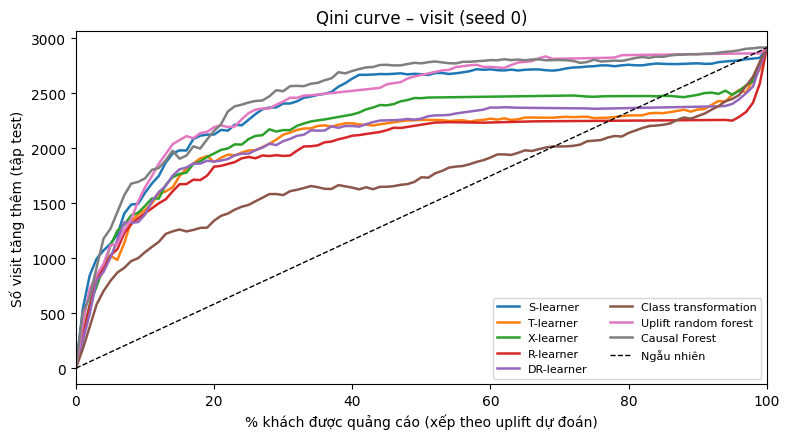

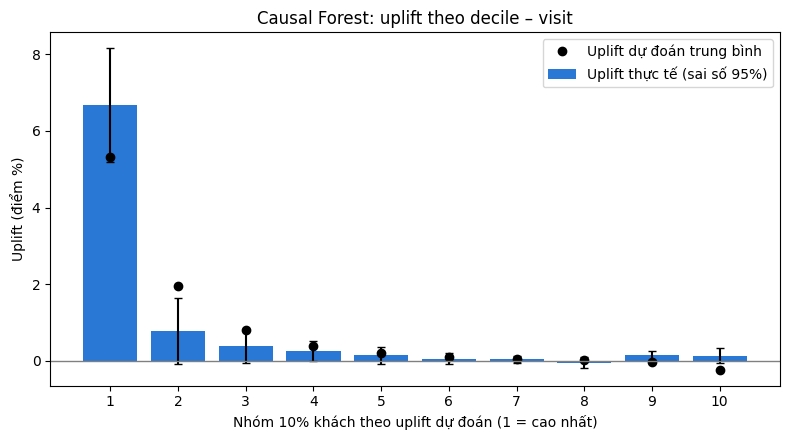

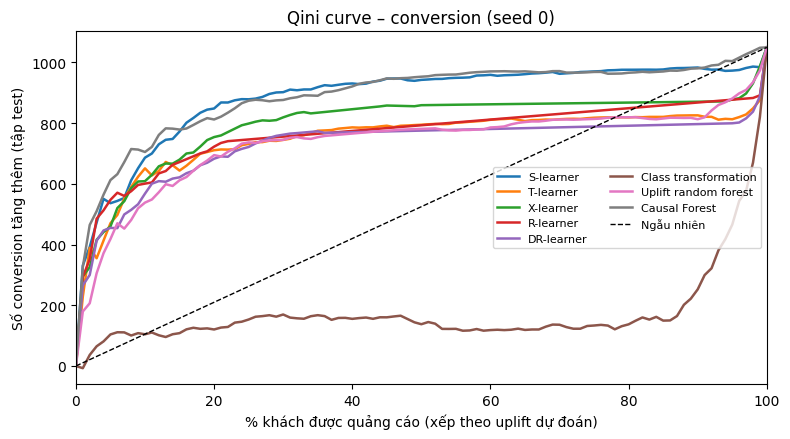

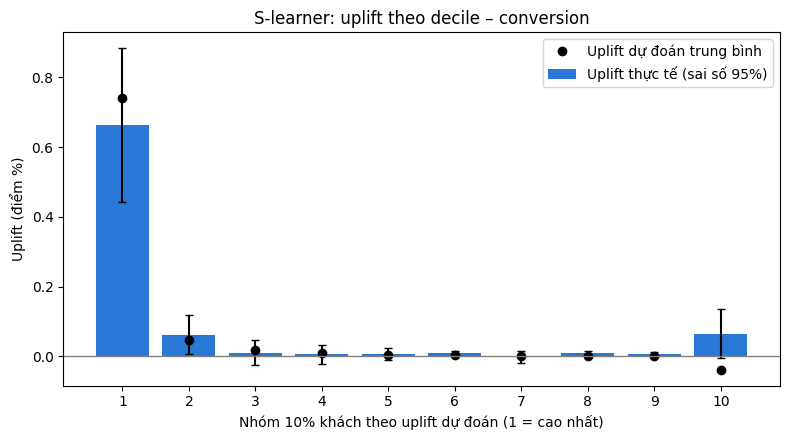

In [ ]:
plt.style.use("default")   # CausalML đổi style matplotlib khi import (chỉ còn 6 màu, đường bị trùng màu); đặt lại mặc định
grid = np.linspace(0, 1, 101)

def load_pred(outcome, name):
    f = np.load(pred_path(outcome, name))
    return f["y"], f["t"], f["score"]

def curve_on_grid(y, t, s):
    x, v = qini_curve(y, t, s)
    return np.interp(grid, x / x[-1], v)

def plot_qini(outcome, names, path):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for k, name in enumerate(names):
        y_, t_, s_ = load_pred(outcome, name)
        ax.plot(grid * 100, curve_on_grid(y_, t_, s_), label=name, linewidth=1.8,
                color=plt.cm.tab10(k % 10), linestyle=["-", "-."][k // 10 % 2])    # 10 màu; hơn 10 đường thì đổi kiểu nét
    end = qini_curve(y_, t_, s_)[1][-1]
    ax.plot(grid * 100, grid * end, color="black", linestyle="--", linewidth=1, label="Ngẫu nhiên")
    ax.set(title=f"Qini curve – {outcome} (seed {SEEDS[0]})", xlim=(0, 100),
           xlabel="% khách được quảng cáo (xếp theo uplift dự đoán)", ylabel=f"Số {outcome} tăng thêm (tập test)")
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.show()

def plot_decile(outcome, name, path):
    y_, t_, s_ = load_pred(outcome, name)
    dec = uplift_by_decile(y_, t_, s_)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(dec.decile, dec.actual_uplift * 100, yerr=1.96 * dec.actual_uplift_se * 100, capsize=3,
           color="#2a78d6", label="Uplift thực tế (sai số 95%)")
    ax.plot(dec.decile, dec.predicted_uplift * 100, "o", color="black", label="Uplift dự đoán trung bình")
    ax.axhline(0, color="grey", linewidth=1)
    ax.set(title=f"{name}: uplift theo decile – {outcome}", xticks=range(1, 11),
           xlabel="Nhóm 10% khách theo uplift dự đoán (1 = cao nhất)", ylabel="Uplift (điểm %)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.show()

for outcome in OUTCOMES:
    names = [m for m in MODELS if os.path.exists(pred_path(outcome, m))]
    plot_qini(outcome, names, os.path.join(FIG_DIR, f"qini_{outcome}.png"))
    best = res[(res.outcome == outcome) & res.model.isin(list(MODELS))].groupby("model")["qini_auc"].mean().idxmax()
    plot_decile(outcome, best, os.path.join(FIG_DIR, f"decile_{outcome}.png"))

if TUAN >= 6 and "conversion" in OUTCOMES:
    names = [m for b in ["T-learner", "S-learner", "X-learner"]
             for m in [b] + [n for n, (_, base) in IMPROVEMENTS.items() if base == b]
             if os.path.exists(pred_path("conversion", m))]
    plot_qini("conversion", names, os.path.join(FIG_DIR, "qini_conversion_A1_A2.png"))
    imp = res[(res.outcome == "conversion") & res.model.isin(list(IMPROVEMENTS))]
    if len(imp):
        best_imp = imp.groupby("model")["qini_auc"].mean().idxmax()
        base = IMPROVEMENTS[best_imp][1]
        for name in [best_imp, base]:
            plot_decile("conversion", name, os.path.join(FIG_DIR, f"decile_conversion_{slug(name)}.png"))

## 10. Đối chiếu tiêu chí: cải tiến so với bản gốc (tuần 6, 8)
Theo yêu cầu của thầy, cải tiến phải cho kết quả cao hơn bài báo gốc. Tiêu chí: Qini AUC trên conversion cao hơn bản gốc ở ít nhất 4/5 seed **và** khoảng tin cậy bootstrap 95% của chênh lệch (tập test của seed đầu) nằm hẳn trên 0. Bảng này là Hình 6.4; bản cuối ở tuần 8 là một phần của Hình 8.2. Mất vài phút vì bootstrap trên tập test lớn.

In [ ]:
def improvement_table(res, pairs, n_boot=None):
    # Tiêu chí: cải tiến có Qini AUC cao hơn bản gốc ở ít nhất 80% số seed (4/5)
    # và khoảng tin cậy bootstrap 95% của chênh lệch (tập test, seed đầu) nằm hẳn trên 0
    rows = []
    for outcome, new, base in pairs:
        r = res[res.outcome == outcome]
        if not {new, base} <= set(r.model):
            continue
        c = compare(res, outcome, new, base)
        need = max(1, int(np.ceil(0.8 * c["n_seeds"])))
        row = {"outcome": outcome, "cải tiến": new, "bản gốc": base,
               "Qini AUC bản gốc": r[r.model == base].qini_auc.mean(),
               "Qini AUC cải tiến": r[r.model == new].qini_auc.mean(),
               "chênh lệch TB": c["mean_diff"], "số seed tốt hơn": f"{c['wins_A']}/{c['n_seeds']}",
               "p-value": c["p_value"], "CI 95% (seed đầu)": "chưa có dự đoán"}
        ci_ok = False
        if os.path.exists(pred_path(outcome, new)) and os.path.exists(pred_path(outcome, base)):
            y_, t_, s_new = load_pred(outcome, new)
            _, _, s_base = load_pred(outcome, base)
            _, lo, hi = bootstrap_diff(y_, t_, s_new, s_base, n_boot=n_boot or N_BOOT)
            row["CI 95% (seed đầu)"] = f"[{lo:+.4f}; {hi:+.4f}]"
            ci_ok = lo > 0
        row["đạt tiêu chí"] = "Đạt" if (c["wins_A"] >= need and ci_ok) else "Chưa đạt"
        rows.append(row)
    return pd.DataFrame(rows)

if TUAN >= 6 and "conversion" in OUTCOMES:
    pairs = [("conversion", name, base) for name, (_, base) in IMPROVEMENTS.items()]
    crit = improvement_table(res, pairs)
    display(crit.round(4))
    crit.to_csv(os.path.join(RESULTS_DIR, "improvement_check.csv"), index=False)
else:
    print("Bỏ qua: đặt TUAN = 6 ở tuần 6")

Bỏ qua: đặt TUAN = 6 ở tuần 6


## 11. Phân tích theo cỡ mẫu (tuần 8)
Lặp lại so sánh bản gốc – cải tiến trong `SIZE_PAIR` khi chỉ học trên 25%, 50% tập train (cùng tập con cho cả hai). Câu hỏi: cải tiến có giúp nhiều hơn khi số conversion càng ít không (Hình 8.3).

In [ ]:
if TUAN >= 8 and "conversion" in OUTCOMES:
    rows = []
    for frac in SIZE_FRACTIONS + [1.0]:
        for name in SIZE_PAIR:
            m = name if frac == 1.0 else size_name(name, frac)
            r = res[(res.outcome == "conversion") & (res.model == m)]
            if len(r):
                rows.append({"tỷ lệ train": frac, "model": name, "n_train": int(r.n_train.mean()),
                             "qini_auc_mean": r.qini_auc.mean(), "qini_auc_std": r.qini_auc.std(ddof=1)})
    size_res = pd.DataFrame(rows)
    display(size_res.round(4))
    size_res.to_csv(os.path.join(RESULTS_DIR, "size_analysis.csv"), index=False)
    fig, ax = plt.subplots(figsize=(7, 4))
    for k, name in enumerate(SIZE_PAIR):
        d = size_res[size_res.model == name]
        ax.errorbar(d["tỷ lệ train"] * 100, d.qini_auc_mean, yerr=d.qini_auc_std.fillna(0), marker="o",
                    capsize=3, color=plt.cm.tab10(k), label=name)
    ax.set(xlabel="% tập train được dùng", ylabel="Qini AUC – conversion",
           title="Bản gốc và cải tiến theo cỡ mẫu train (TB ± độ lệch chuẩn)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, "size_analysis.png"), dpi=200)
    plt.show()
    size_pairs = [("conversion", size_name(SIZE_PAIR[1], f), size_name(SIZE_PAIR[0], f)) for f in SIZE_FRACTIONS]
    display(improvement_table(res, size_pairs).round(4))
else:
    print("Bỏ qua: đặt TUAN = 8 ở tuần 8")

Bỏ qua: đặt TUAN = 8 ở tuần 8


## 12. Ghi chú
- Cải tiến A3 (TARNet + phễu) và P (DESCN cân bằng propensity) nằm trong notebook `DESCN_Criteo.ipynb`, có bảng đối chiếu tiêu chí riêng.
- Mỗi cải tiến phải giải thích được: vì sao có thể tốt hơn, khác bản gốc ở dòng code nào, kết quả theo từng seed.
- Kết quả không đạt tiêu chí vẫn báo cáo đúng như thật, kèm phân tích nguyên nhân (mục 11 và thí nghiệm loại trừ ở notebook DESCN).